# Proyecto · Clase 1 — Conocer los datos (y una primera IA muy tonta)

**La misión del curso:** al final vas a dibujar un número con el mouse y **tu propia red neuronal**, escrita por ti
en Python y sin librerías mágicas, va a adivinar qué número es.

Cada clase agrega una pieza. Hoy:
1. Conocer los datos: 70 000 dígitos escritos a mano (MNIST).
2. Entender que **una imagen es solo una tabla de números**.
3. Construir una primera «IA» que ya acierta 8 de cada 10… sin ninguna neurona.

> Las celdas con `...` son tuyas: complétalas y ejecuta la celda de comprobación que viene después (✅ o ❌).

In [1]:
# Si estás en Google Colab, esto baja las herramientas del proyecto (en tu computadora no hace nada).
import os, urllib.request
if not os.path.exists("digitos.py"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/datahuba/curso-redes-neuronales/main/proyecto/digitos.py", "digitos.py")

import numpy as np
import matplotlib.pyplot as plt
from digitos import cargar_mnist, mostrar, ok

## 1. Cargar los datos
`cargar_mnist()` devuelve cuatro cosas:
- `X_train`, `y_train`: 60 000 imágenes **para aprender** y el número correcto de cada una (la *etiqueta*).
- `X_test`, `y_test`: 10 000 imágenes **para el examen**. La IA nunca las ve mientras aprende.

¿Por qué separar? Igual que en el colegio: si el examen tiene las mismas preguntas que la práctica, no sabes si
el alumno entendió o solo memorizó.

In [2]:
X_train, y_train, X_test, y_test = cargar_mnist()
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape, " y_test: ", y_test.shape)

X_train: (60000, 28, 28)  y_train: (60000,)
X_test:  (10000, 28, 28)  y_test:  (10000,)


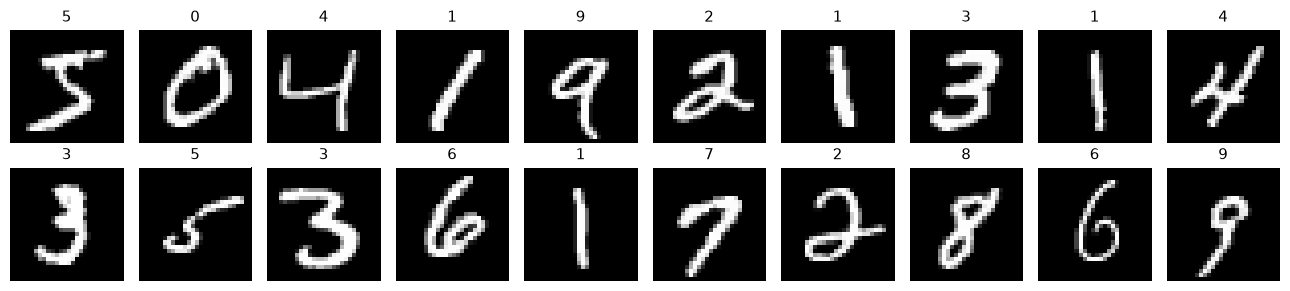

In [3]:
mostrar(X_train[:20], titulos=y_train[:20])

## 2. Una imagen es una tabla de números
Cada imagen es una tabla de **28 × 28** números: 0 es negro, 255 es blanco. Mira el centro de la primera imagen:

In [4]:
np.set_printoptions(linewidth=200)
print(X_train[0][4:24, 4:24])

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   3  18  18  18 126 136 175  26 166 255 247 127]
 [  0   0   0   0  30  36  94 154 170 253 253 253 253 253 225 172 253 242 195  64]
 [  0   0   0  49 238 253 253 253 253 253 253 253 253 251  93  82  82  56  39   0]
 [  0   0   0  18 219 253 253 253 253 253 198 182 247 241   0   0   0   0   0   0]
 [  0   0   0   0  80 156 107 253 253 205  11   0  43 154   0   0   0   0   0   0]
 [  0   0   0   0   0  14   1 154 253  90   0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0 139 253 190   2   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0  11 190 253  70   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0  35 241 225 160 108   1   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0  81 240 253 253 119  25   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0  45 186 253 253 150  27   0   0   0   0]
 [  

✏️ **Ejercicio 1.** ¿Cuántos ejemplos hay de cada dígito? Usa `np.bincount(y_train)`.

In [5]:
cuantos = np.bincount(y_train)
print(cuantos)


[5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [6]:
ok(len(cuantos) == 10 and cuantos.sum() == 60000, "hay unos 6 000 ejemplos de cada dígito")

✅ hay unos 6 000 ejemplos de cada dígito


✏️ **Ejercicio 2. Preparar los datos para la red.** Las redes trabajan con **vectores** y con números pequeños:
1. «Aplana» cada imagen: de 28 × 28 a una fila de 784 números → `reshape(cantidad, 784)`.
2. Divide entre 255 para que todo quede entre 0 y 1.

In [7]:
X = X_train.reshape(len(X_train), 784) / 255.0      # 60000 x 784, valores entre 0 y 1
Xt = X_test.reshape(len(X_test), 784) / 255.0       # 10000 x 784, valores entre 0 y 1


In [8]:
ok(X.shape == (60000, 784) and Xt.shape == (10000, 784), "las imágenes son filas de 784")
ok(X.max() == 1.0 and X.min() == 0.0, "los valores van de 0 a 1")

✅ las imágenes son filas de 784
✅ los valores van de 0 a 1


## 3. Nuestra primera IA: «el promedio de cada número»
Idea: si promediamos los 6 000 «tres», sale algo así como **el tres típico** (una *plantilla*).
Para adivinar una imagen nueva, buscamos **a qué plantilla se parece más**.

Nadie le escribió reglas («un 1 es una raya vertical»). Las plantillas **salen de los ejemplos**.
Eso es *aprender de datos*, la idea central de todo el curso.

✏️ **Ejercicio 3.** Calcula la plantilla de cada dígito: el promedio de las filas de `X` cuya etiqueta es `d`.
Pista: `X[y_train == d]` se queda solo con las imágenes del dígito `d`, y `.mean(axis=0)` promedia filas.

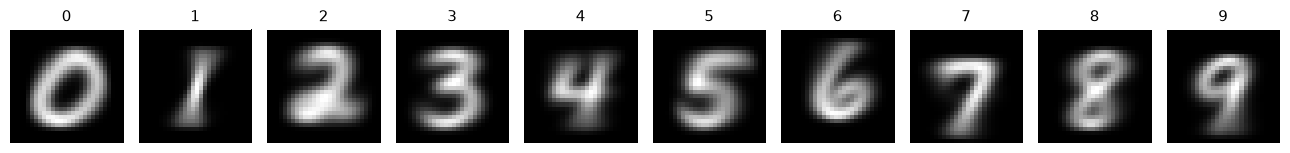

In [9]:
plantillas = np.zeros((10, 784))
for d in range(10):
    plantillas[d] = X[y_train == d].mean(axis=0)
mostrar(plantillas, titulos=range(10))


In [10]:
ok(np.allclose(plantillas[1], X[y_train == 1].mean(axis=0)), "las plantillas son los promedios")

✅ las plantillas son los promedios


✏️ **Ejercicio 4.** Escribe `predecir(x)`: compara la imagen `x` con las 10 plantillas y devuelve el dígito de la
plantilla **más parecida**. «Parecido» = la suma de las diferencias al cuadrado es pequeña:

`distancias = ((plantillas - x) ** 2).sum(axis=1)` → 10 números. El más chico gana: `np.argmin(...)`.

In [11]:
def predecir(x):
    distancias = ((plantillas - x) ** 2).sum(axis=1)
    return np.argmin(distancias)

print("La IA dice:", predecir(Xt[0]), "  · La respuesta correcta es:", y_test[0])


La IA dice: 7   · La respuesta correcta es: 7


## 4. El examen
La **precisión** es el porcentaje de imágenes del examen que acierta.

In [12]:
predicciones = np.array([predecir(x) for x in Xt])
precision = (predicciones == y_test).mean()
print(f"Precisión: {precision:.1%}")
ok(precision > 0.8, "la IA de plantillas acierta más del 80 %")

Precisión: 82.0%
✅ la IA de plantillas acierta más del 80 %


¿Dónde se equivoca? Arriba de cada imagen: **lo que dijo la IA → lo correcto**.

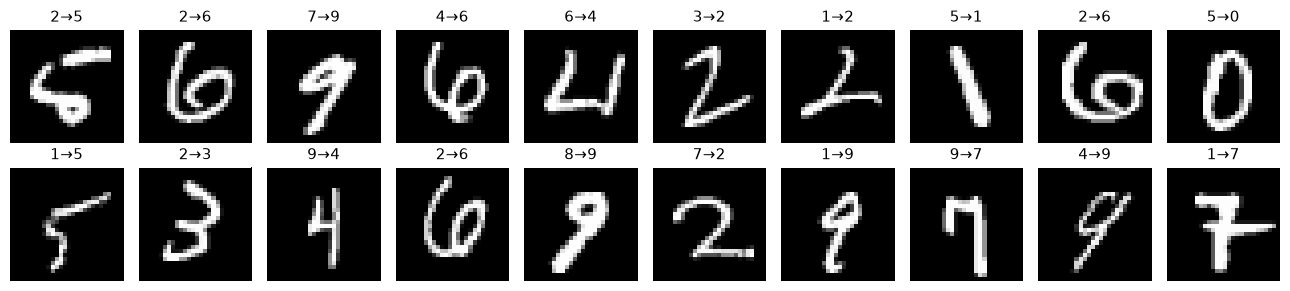

In [13]:
errores = np.where(predicciones != y_test)[0][:20]
mostrar(Xt[errores], titulos=[f"{predicciones[i]}→{y_test[i]}" for i in errores])

## Para pensar (y comentar en clase)
1. ¿Por qué crees que confunde esos números? ¿Tú los confundirías?
2. Las plantillas **nunca cambian**: si la IA se equivoca, no aprende nada del error. ¿Cómo podría corregirse sola?

Esa es la pregunta de la **Clase 2**: una *neurona* que ajusta sus números cada vez que se equivoca.

| Palabra | Qué significa en nuestro proyecto |
|---|---|
| dato / ejemplo | una imagen (784 números) |
| etiqueta | el número correcto de esa imagen |
| entrenamiento | las 60 000 imágenes de las que se aprende |
| prueba (examen) | las 10 000 que solo se usan para medir |
| precisión | % de aciertos en la prueba |